In [1]:
# Cell 1
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import pymupdf

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PDF_PATH = PROJECT_ROOT / "data" / "hld_documents" / "sample_autosar_hld.pdf"

ARCHITECTURE_PATH = (
    PROJECT_ROOT / "outputs" / "extracted_entities"
    / "architecture_knowledge.json"
)

PAGES_PATH = PROJECT_ROOT / "data" / "processed" / "extracted_pages.json"

OUTPUT_DIR = PROJECT_ROOT / "eval" / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("PDF exists:", PDF_PATH.exists())
print("Architecture JSON exists:", ARCHITECTURE_PATH.exists())
print("Extracted pages JSON exists:", PAGES_PATH.exists())

Project root: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant
PDF exists: True
Architecture JSON exists: True
Extracted pages JSON exists: True


In [2]:
# Cell 2
with open(ARCHITECTURE_PATH, "r", encoding="utf-8") as file:
    architecture_data = json.load(file)

print("Architecture dataset loaded successfully.")
print("\nArchitecture entity categories:")

for category, records in architecture_data.items():
    if isinstance(records, list):
        print(f"{category}: {len(records)} records")

Architecture dataset loaded successfully.

Architecture entity categories:
components: 3 records
ports: 7 records
interfaces: 3 records
data_flows: 5 records
functional_flows: 6 records
dependencies: 3 records
architecture_relationships: 3 records


In [3]:
# Cell 3
entity_counts = {
    category: len(records)
    for category, records in architecture_data.items()
    if isinstance(records, list)
}

dataset_profile = pd.DataFrame(
    list(entity_counts.items()),
    columns=["Entity Type", "Record Count"]
)

total_records = dataset_profile["Record Count"].sum()

dataset_profile["Percentage"] = (
    dataset_profile["Record Count"] / total_records * 100
).round(2)

display(dataset_profile)

print("\nTotal extracted records:", total_records)
print("Number of entity categories:", len(dataset_profile))

,Entity Type,Record Count,Percentage
0,components,3,10.00
1,ports,7,23.33
2,interfaces,3,10.00
3,data_flows,5,16.67
4,functional_flows,6,20.00
5,dependencies,3,10.00
6,architecture_relationships,3,10.00



Total extracted records: 30
Number of entity categories: 7


In [4]:
# Cell 4
with pymupdf.open(PDF_PATH) as document:
    pdf_metadata = document.metadata
    page_count = len(document)

pdf_profile = {
    "Document": PDF_PATH.name,
    "Page Count": page_count,
    "File Size (KB)": round(
        PDF_PATH.stat().st_size / 1024, 2
    ),
    "Title": pdf_metadata.get("title"),
    "Author": pdf_metadata.get("author")
}

for key, value in pdf_profile.items():
    print(f"{key}: {value}")

Document: sample_autosar_hld.pdf
Page Count: 5
File Size (KB): 31.86
Title: 
Author: 


In [6]:
# Cell 5
with open(PAGES_PATH, "r", encoding="utf-8") as file:
    extracted_pages = json.load(file)

# Support both list-based and dictionary-based JSON formats
if isinstance(extracted_pages, list):
    page_records = extracted_pages
elif isinstance(extracted_pages, dict):
    page_records = extracted_pages.get("pages", [])
else:
    raise ValueError("Unexpected format in extracted_pages.json")

pages_df = pd.DataFrame(page_records)

# Handle cases where the JSON uses a different text field
if "text" not in pages_df.columns:
    raise KeyError(
        f"'text' field not found. Available columns: "
        f"{pages_df.columns.tolist()}"
    )

pages_df["text"] = pages_df["text"].fillna("").astype(str)
pages_df["text_length"] = pages_df["text"].str.len()

# Display available page information
display(pages_df.head())

print("\nTotal pages analyzed:", len(pages_df))

if "needs_ocr" in pages_df.columns:
    print(
        "Pages flagged for OCR:",
        int(pages_df["needs_ocr"].fillna(False).astype(bool).sum())
    )
else:
    print("OCR status: Not available in the extracted page records.")

print(
    "Pages with extracted text:",
    int((pages_df["text_length"] > 0).sum())
)

print(
    "Average characters per page:",
    round(pages_df["text_length"].mean(), 2)
)

,document,page,text,character_count,needs_ocr_review,text_length
0,sample_autosar_hld.pdf,1,Synthetic AUTOSAR HLD — Training/Demonstration...,940,False,940
1,sample_autosar_hld.pdf,2,Synthetic AUTOSAR HLD — Training/Demonstration...,836,False,836
2,sample_autosar_hld.pdf,3,Synthetic AUTOSAR HLD — Training/Demonstration...,829,False,829
3,sample_autosar_hld.pdf,4,Synthetic AUTOSAR HLD — Training/Demonstration...,927,False,927
4,sample_autosar_hld.pdf,5,Synthetic AUTOSAR HLD — Training/Demonstration...,1177,False,1177



Total pages analyzed: 5
OCR status: Not available in the extracted page records.
Pages with extracted text: 5
Average characters per page: 941.8


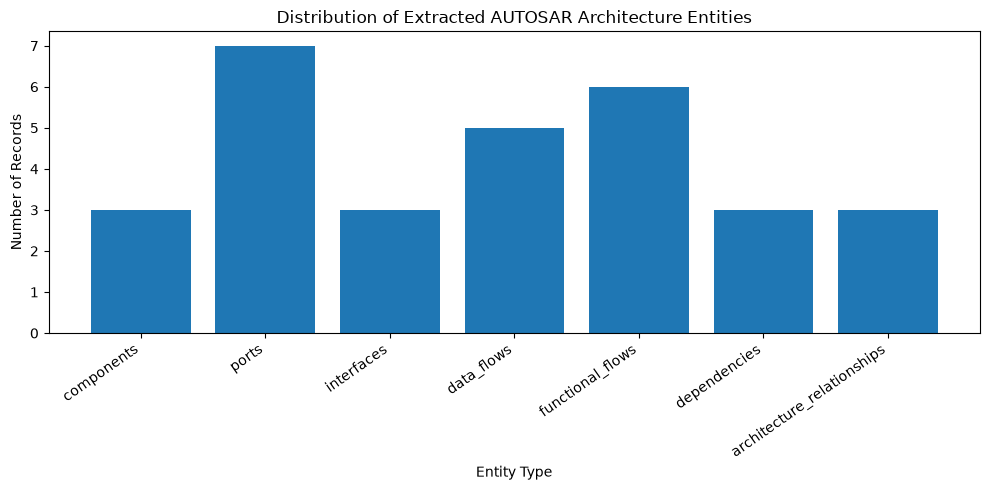

Chart saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\entity_distribution.png


In [7]:
# Cell 6
plt.figure(figsize=(10, 5))

plt.bar(
    dataset_profile["Entity Type"],
    dataset_profile["Record Count"]
)

plt.title("Distribution of Extracted AUTOSAR Architecture Entities")
plt.xlabel("Entity Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plot_path = OUTPUT_DIR / "entity_distribution.png"
plt.savefig(plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", plot_path)

In [8]:
# Cell 7
entity_profile_path = OUTPUT_DIR / "notebook06_entity_profile.csv"

dataset_profile.to_csv(entity_profile_path, index=False)

print("Entity profile saved successfully.")
print("File:", entity_profile_path)
print("Total records:", dataset_profile["Record Count"].sum())
print("Entity categories:", len(dataset_profile))

Entity profile saved successfully.
File: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_entity_profile.csv
Total records: 30
Entity categories: 7


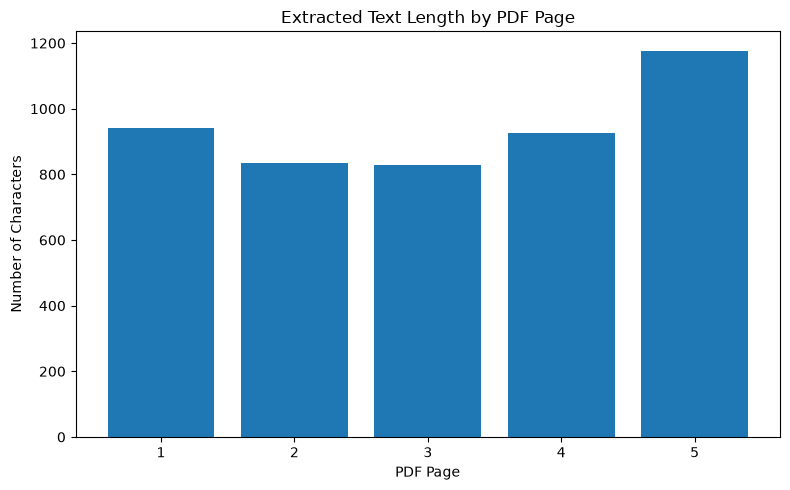

Page-level chart saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\page_text_length.png
Minimum text length: 829
Maximum text length: 1177
Average text length: 941.8


In [9]:
# Cell 8
plt.figure(figsize=(8, 5))

plt.bar(
    pages_df["page"].astype(str),
    pages_df["text_length"]
)

plt.title("Extracted Text Length by PDF Page")
plt.xlabel("PDF Page")
plt.ylabel("Number of Characters")
plt.tight_layout()

page_plot_path = OUTPUT_DIR / "page_text_length.png"
plt.savefig(page_plot_path, dpi=150, bbox_inches="tight")
plt.show()

print("Page-level chart saved to:", page_plot_path)
print("Minimum text length:", pages_df["text_length"].min())
print("Maximum text length:", pages_df["text_length"].max())
print("Average text length:", round(pages_df["text_length"].mean(), 2))

In [11]:
# Cell 9
total_pages = len(pages_df)

pages_with_text = int(
    (pages_df["text_length"] > 0).sum()
)

if "needs_ocr_review" in pages_df.columns:
    ocr_review_count = int(
        pages_df["needs_ocr_review"]
        .fillna(False)
        .astype(bool)
        .sum()
    )
else:
    ocr_review_count = None

print("Total pages:", total_pages)
print("Pages with extracted text:", pages_with_text)
print(
    "Text extraction coverage (%):",
    round(pages_with_text / total_pages * 100, 2)
    if total_pages else 0
)

if ocr_review_count is not None:
    print("Pages flagged for OCR review:", ocr_review_count)
else:
    print("OCR review field is unavailable.")

# Show the pages that may need further inspection
if ocr_review_count is not None:
    review_pages = pages_df.loc[
        pages_df["needs_ocr_review"].fillna(False).astype(bool),
        ["document", "page", "text_length"]
    ]

    if review_pages.empty:
        print("No pages are flagged for OCR review.")
    else:
        print("\nPages requiring review:")
        display(review_pages)

Total pages: 5
Pages with extracted text: 5
Text extraction coverage (%): 100.0
Pages flagged for OCR review: 0
No pages are flagged for OCR review.


In [12]:
# Cell 10
eda_summary = {
    "document": PDF_PATH.name,
    "page_count": int(len(pages_df)),
    "total_architecture_records": int(
        dataset_profile["Record Count"].sum()
    ),
    "entity_categories": int(len(dataset_profile)),
    "pages_with_text": int(
        (pages_df["text_length"] > 0).sum()
    ),
    "average_characters_per_page": round(
        float(pages_df["text_length"].mean()), 2
    ),
    "minimum_characters_per_page": int(
        pages_df["text_length"].min()
    ),
    "maximum_characters_per_page": int(
        pages_df["text_length"].max()
    ),
    "pages_flagged_for_ocr_review": (
        int(
            pages_df["needs_ocr_review"]
            .fillna(False)
            .astype(bool)
            .sum()
        )
        if "needs_ocr_review" in pages_df.columns
        else None
    )
}

summary_path = OUTPUT_DIR / "notebook06_eda_summary.json"

with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(eda_summary, file, indent=4)

print("EDA summary saved to:", summary_path)
print("\nEDA Summary:")
print(json.dumps(eda_summary, indent=4))

EDA summary saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_eda_summary.json

EDA Summary:
{
    "document": "sample_autosar_hld.pdf",
    "page_count": 5,
    "total_architecture_records": 30,
    "entity_categories": 7,
    "pages_with_text": 5,
    "average_characters_per_page": 941.8,
    "minimum_characters_per_page": 829,
    "maximum_characters_per_page": 1177,
    "pages_flagged_for_ocr_review": 0
}


In [13]:
# Cell 11
print("ARCHITECTURE RECORD STRUCTURE")
print("=" * 60)

for category, records in architecture_data.items():
    if not isinstance(records, list):
        continue

    print(f"\nCategory: {category}")
    print("Number of records:", len(records))

    if records:
        print("Available fields:", list(records[0].keys()))
        print("Sample record:")
        print(json.dumps(records[0], indent=4, ensure_ascii=False))

ARCHITECTURE RECORD STRUCTURE

Category: components
Number of records: 3
Available fields: ['name', 'type', 'document', 'page', 'section_number', 'section_title', 'role', 'inputs', 'outputs']
Sample record:
{
    "name": "BatteryMonitor",
    "type": "SoftwareComponent",
    "document": "sample_autosar_hld.pdf",
    "page": 2,
    "section_number": "3",
    "section_title": "Software Components",
    "role": "Battery measurement and status",
    "inputs": [
        "BatteryVoltage",
        "BatteryTemperature"
    ],
    "outputs": [
        "BatteryStatus"
    ]
}

Category: ports
Number of records: 7
Available fields: ['name', 'component', 'direction', 'description', 'document', 'page', 'section_number', 'section_title', 'subsection_number']
Sample record:
{
    "name": "P_BatteryVoltage",
    "component": "BatteryMonitor",
    "direction": "Provider",
    "description": "battery voltage information.",
    "document": "sample_autosar_hld.pdf",
    "page": 3,
    "section_number": "5

In [14]:
# Cell 12
quality_records = []

for category, records in architecture_data.items():
    if not isinstance(records, list):
        continue

    for record_index, record in enumerate(records):
        if not isinstance(record, dict):
            quality_records.append({
                "Entity Type": category,
                "Record Index": record_index,
                "Field": "<record>",
                "Missing": True
            })
            continue

        for field, value in record.items():
            is_missing = (
                value is None
                or (isinstance(value, str) and not value.strip())
            )

            quality_records.append({
                "Entity Type": category,
                "Record Index": record_index,
                "Field": field,
                "Missing": is_missing
            })

quality_df = pd.DataFrame(quality_records)

if not quality_df.empty:
    missing_summary = (
        quality_df.groupby(["Entity Type", "Field"])["Missing"]
        .agg(["sum", "count"])
        .reset_index()
    )

    missing_summary = missing_summary.rename(columns={
        "sum": "Missing Values",
        "count": "Total Records"
    })

    missing_summary["Missing Percentage"] = (
        missing_summary["Missing Values"]
        / missing_summary["Total Records"] * 100
    ).round(2)

    display(
        missing_summary[
            missing_summary["Missing Values"] > 0
        ].reset_index(drop=True)
    )

    total_missing = int(quality_df["Missing"].sum())
    total_fields = len(quality_df)

    print("Total field instances checked:", total_fields)
    print("Missing or empty field instances:", total_missing)

    if total_missing == 0:
        print("Result: No missing or empty field values found.")
else:
    print("No architecture records were available for analysis.")

,Entity Type,Field,Missing Values,Total Records,Missing Percentage


Total field instances checked: 230
Missing or empty field instances: 0
Result: No missing or empty field values found.


In [15]:
# Cell 13
duplicate_summary = []
duplicate_records = []

for category, records in architecture_data.items():
    if not isinstance(records, list):
        continue

    seen_records = {}

    for record_index, record in enumerate(records):
        record_signature = json.dumps(
            record,
            sort_keys=True,
            ensure_ascii=False,
            default=str
        )

        if record_signature in seen_records:
            duplicate_records.append({
                "Entity Type": category,
                "First Record Index": seen_records[record_signature],
                "Duplicate Record Index": record_index,
                "Record": record
            })
        else:
            seen_records[record_signature] = record_index

    duplicate_summary.append({
        "Entity Type": category,
        "Total Records": len(records),
        "Duplicate Records": sum(
            1 for item in duplicate_records
            if item["Entity Type"] == category
        )
    })

duplicate_df = pd.DataFrame(duplicate_summary)

display(duplicate_df)

print(
    "\nTotal exact duplicate records:",
    len(duplicate_records)
)

if duplicate_records:
    print("\nDuplicate record details:")
    display(pd.DataFrame(duplicate_records))
else:
    print("No exact duplicate records detected.")

,Entity Type,Total Records,Duplicate Records
0,components,3,0
1,ports,7,0
2,interfaces,3,0
3,data_flows,5,0
4,functional_flows,6,0
5,dependencies,3,0
6,architecture_relationships,3,0



Total exact duplicate records: 0
No exact duplicate records detected.


In [16]:
# Cell 14
def normalize_name(value):
    if value is None:
        return None

    if not isinstance(value, str):
        return None

    value = value.strip()
    return value.casefold() if value else None


component_records = architecture_data.get("components", [])

component_names = set()

for record in component_records:
    if not isinstance(record, dict):
        continue

    for field in ["name", "component", "component_name"]:
        normalized = normalize_name(record.get(field))

        if normalized:
            component_names.add(normalized)

reference_fields = {
    "dependencies": [
        "dependent_component",
        "dependency_component",
        "source_component",
        "target_component"
    ],
    "architecture_relationships": [
        "source_component",
        "target_component",
        "from_component",
        "to_component"
    ],
    "data_flows": [
        "source_component",
        "target_component",
        "producer",
        "consumer"
    ],
    "functional_flows": [
        "component",
        "source_component",
        "target_component"
    ]
}

reference_results = []

for category, fields in reference_fields.items():
    records = architecture_data.get(category, [])

    if not isinstance(records, list):
        continue

    for record_index, record in enumerate(records):
        if not isinstance(record, dict):
            continue

        for field in fields:
            if field not in record:
                continue

            referenced_name = normalize_name(record[field])

            if not referenced_name:
                continue

            reference_results.append({
                "Entity Type": category,
                "Record Index": record_index,
                "Reference Field": field,
                "Referenced Name": record[field],
                "Found in Components": (
                    referenced_name in component_names
                )
            })

reference_df = pd.DataFrame(reference_results)

if not reference_df.empty:
    display(reference_df)

    unresolved_references = reference_df[
        ~reference_df["Found in Components"]
    ]

    print("\nComponent names found:", len(component_names))
    print("References checked:", len(reference_df))
    print("Unresolved component references:", len(unresolved_references))

    if not unresolved_references.empty:
        print(
            "\nReview these references. Some may be external systems "
            "rather than missing internal components."
        )
        display(unresolved_references)
else:
    print("No matching component-reference fields were found.")
    print("Inspect Cell 11 to identify the actual reference fields.")

,Entity Type,Record Index,Reference Field,Referenced Name,Found in Components
0,dependencies,0,dependent_component,ThermalController,True
1,dependencies,0,dependency_component,BatteryMonitor,True
2,dependencies,1,dependent_component,Dashboard,True
3,dependencies,1,dependency_component,BatteryMonitor,True
4,dependencies,2,dependent_component,CoolingSystem,False
5,dependencies,2,dependency_component,ThermalController,True
6,architecture_relationships,0,source_component,BatteryMonitor,True
7,architecture_relationships,0,target_component,ThermalController,True
8,architecture_relationships,1,source_component,BatteryMonitor,True
9,architecture_relationships,1,target_component,Dashboard,True



Component names found: 3
References checked: 12
Unresolved component references: 2

Review these references. Some may be external systems rather than missing internal components.


,Entity Type,Record Index,Reference Field,Referenced Name,Found in Components
4,dependencies,2,dependent_component,CoolingSystem,False
11,architecture_relationships,2,target_component,CoolingSystem,False


In [17]:
# Cell 15
data_quality_report = {
    "document": PDF_PATH.name,
    "architecture_categories": len(entity_counts),
    "total_architecture_records": int(
        dataset_profile["Record Count"].sum()
    ),
    "missing_or_empty_field_instances": int(
        quality_df["Missing"].sum()
    ) if not quality_df.empty else 0,
    "exact_duplicate_records": len(duplicate_records),
    "component_names_identified": len(component_names),
    "component_references_checked": len(reference_results),
    "unresolved_component_references": (
        int((~reference_df["Found in Components"]).sum())
        if not reference_df.empty else 0
    ),
    "note": (
        "Unresolved references require manual review because they "
        "may represent external systems or schema differences."
    )
}

quality_report_path = OUTPUT_DIR / "notebook06_data_quality_report.json"

with open(quality_report_path, "w", encoding="utf-8") as file:
    json.dump(
        data_quality_report,
        file,
        indent=4,
        ensure_ascii=False
    )

print("DATA QUALITY REPORT")
print("=" * 50)
print(json.dumps(data_quality_report, indent=4, ensure_ascii=False))
print("\nReport saved to:", quality_report_path)

DATA QUALITY REPORT
{
    "document": "sample_autosar_hld.pdf",
    "architecture_categories": 7,
    "total_architecture_records": 30,
    "missing_or_empty_field_instances": 0,
    "exact_duplicate_records": 0,
    "component_names_identified": 3,
    "component_references_checked": 12,
    "unresolved_component_references": 2,
    "note": "Unresolved references require manual review because they may represent external systems or schema differences."
}

Report saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_data_quality_report.json


In [18]:
# Cell 16
print("UNRESOLVED COMPONENT REFERENCES")
print("=" * 60)

if not reference_df.empty:
    unresolved_references = reference_df[
        ~reference_df["Found in Components"]
    ].copy()

    if unresolved_references.empty:
        print("No unresolved component references found.")
    else:
        display(unresolved_references)

        print("\nKnown internal components:")
        for component in sorted(component_names):
            print("-", component)

        print("\nReview each unresolved reference to determine whether it is:")
        print("1. An external system")
        print("2. A missing internal component")
        print("3. A field-mapping or naming inconsistency")
else:
    print("No component references were available for inspection.")

UNRESOLVED COMPONENT REFERENCES


,Entity Type,Record Index,Reference Field,Referenced Name,Found in Components
4,dependencies,2,dependent_component,CoolingSystem,False
11,architecture_relationships,2,target_component,CoolingSystem,False



Known internal components:
- batterymonitor
- dashboard
- thermalcontroller

Review each unresolved reference to determine whether it is:
1. An external system
2. A missing internal component
3. A field-mapping or naming inconsistency


In [19]:
# Cell 17
print("UNRESOLVED REFERENCE DETAILS")
print("=" * 60)

unresolved_references = reference_df[
    ~reference_df["Found in Components"]
].copy()

if unresolved_references.empty:
    print("No unresolved references found.")
else:
    for index, row in unresolved_references.iterrows():
        print(f"\nReference {index + 1}")
        print("Entity category:", row["Entity Type"])
        print("Record index:", row["Record Index"])
        print("Reference field:", row["Reference Field"])
        print("Referenced name:", row["Referenced Name"])

print("\nKnown internal components:")
for component in sorted(component_names):
    print("-", component)

UNRESOLVED REFERENCE DETAILS

Reference 5
Entity category: dependencies
Record index: 2
Reference field: dependent_component
Referenced name: CoolingSystem

Reference 12
Entity category: architecture_relationships
Record index: 2
Reference field: target_component
Referenced name: CoolingSystem

Known internal components:
- batterymonitor
- dashboard
- thermalcontroller


In [20]:
# Cell 18
print("COOLINGSYSTEM REFERENCE INSPECTION")
print("=" * 60)

for category in ["dependencies", "architecture_relationships"]:
    records = architecture_data.get(category, [])

    for index, record in enumerate(records):
        if not isinstance(record, dict):
            continue

        record_text = json.dumps(record, ensure_ascii=False)

        if "CoolingSystem" in record_text:
            print(f"\nCategory: {category}")
            print(f"Record index: {index}")
            print(json.dumps(record, indent=4, ensure_ascii=False))

COOLINGSYSTEM REFERENCE INSPECTION

Category: dependencies
Record index: 2
{
    "dependent_component": "CoolingSystem",
    "dependency_component": "ThermalController",
    "data_element": "CoolingRequest",
    "document": "sample_autosar_hld.pdf",
    "page": 4,
    "section_number": "9",
    "section_title": "Dependency Mapping"
}

Category: architecture_relationships
Record index: 2
{
    "source_component": "ThermalController",
    "target_component": "CoolingSystem",
    "interface": "CoolingRequestInterface",
    "document": "sample_autosar_hld.pdf",
    "page": 5,
    "section_number": "10",
    "section_title": "Architecture Relationships"
}


In [21]:
# Cell 19
internal_components = {
    "batterymonitor",
    "dashboard",
    "thermalcontroller"
}

external_entities = {
    "coolingsystem"
}

print("Internal components:", len(internal_components))
print("External entities:", len(external_entities))

print("\nInternal components:")
for name in sorted(internal_components):
    print("-", name)

print("\nExternal entities:")
for name in sorted(external_entities):
    print("-", name)

Internal components: 3
External entities: 1

Internal components:
- batterymonitor
- dashboard
- thermalcontroller

External entities:
- coolingsystem


In [22]:
# Cell 20
classified_references = reference_df.copy()

def classify_reference(row):
    name = normalize_name(row["Referenced Name"])

    if name in internal_components:
        return "Internal component"

    if name in external_entities:
        return "Known external entity"

    return "Unclassified reference"

classified_references["Classification"] = (
    classified_references.apply(classify_reference, axis=1)
)

display(classified_references)

print("\nREFERENCE CLASSIFICATION SUMMARY")
print(
    classified_references["Classification"]
    .value_counts()
    .to_string()
)

print(
    "\nKnown external references:",
    int(
        (
            classified_references["Classification"]
            == "Known external entity"
        ).sum()
    )
)

print(
    "Unclassified references:",
    int(
        (
            classified_references["Classification"]
            == "Unclassified reference"
        ).sum()
    )
)

,Entity Type,Record Index,Reference Field,Referenced Name,Found in Components,Classification
0,dependencies,0,dependent_component,ThermalController,True,Internal component
1,dependencies,0,dependency_component,BatteryMonitor,True,Internal component
2,dependencies,1,dependent_component,Dashboard,True,Internal component
3,dependencies,1,dependency_component,BatteryMonitor,True,Internal component
4,dependencies,2,dependent_component,CoolingSystem,False,Known external entity
5,dependencies,2,dependency_component,ThermalController,True,Internal component
6,architecture_relationships,0,source_component,BatteryMonitor,True,Internal component
7,architecture_relationships,0,target_component,ThermalController,True,Internal component
8,architecture_relationships,1,source_component,BatteryMonitor,True,Internal component
9,architecture_relationships,1,target_component,Dashboard,True,Internal component



REFERENCE CLASSIFICATION SUMMARY
Classification
Internal component       10
Known external entity     2

Known external references: 2
Unclassified references: 0


In [23]:
# Cell 21
total_references = len(classified_references)

internal_reference_count = int(
    (
        classified_references["Classification"]
        == "Internal component"
    ).sum()
)

external_reference_count = int(
    (
        classified_references["Classification"]
        == "Known external entity"
    ).sum()
)

unclassified_reference_count = int(
    (
        classified_references["Classification"]
        == "Unclassified reference"
    ).sum()
)

reference_summary = pd.DataFrame([
    {
        "Reference Type": "Internal component",
        "Count": internal_reference_count
    },
    {
        "Reference Type": "Known external entity",
        "Count": external_reference_count
    },
    {
        "Reference Type": "Unclassified",
        "Count": unclassified_reference_count
    }
])

reference_summary["Percentage"] = (
    reference_summary["Count"] / total_references * 100
).round(2) if total_references else 0

display(reference_summary)

print("\nTotal references checked:", total_references)
print(
    "Classified references:",
    internal_reference_count + external_reference_count
)

,Reference Type,Count,Percentage
0,Internal component,10,83.33
1,Known external entity,2,16.67
2,Unclassified,0,0.00



Total references checked: 12
Classified references: 12


In [24]:
# Cell 22
updated_quality_report = {
    "document": PDF_PATH.name,
    "architecture_categories": len(entity_counts),
    "total_architecture_records": int(
        dataset_profile["Record Count"].sum()
    ),
    "missing_or_empty_field_instances": int(
        quality_df["Missing"].sum()
    ) if not quality_df.empty else 0,
    "exact_duplicate_records": len(duplicate_records),
    "internal_components_identified": len(internal_components),
    "external_entities_documented": len(external_entities),
    "component_references_checked": total_references,
    "internal_component_references": internal_reference_count,
    "known_external_references": external_reference_count,
    "unclassified_references": unclassified_reference_count,
    "external_entity_assumption": (
        "CoolingSystem is treated as an external entity for this "
        "synthetic demonstration and should be verified against "
        "the source HLD."
    )
}

updated_report_path = (
    OUTPUT_DIR / "notebook06_data_quality_report.json"
)

with open(updated_report_path, "w", encoding="utf-8") as file:
    json.dump(
        updated_quality_report,
        file,
        indent=4,
        ensure_ascii=False
    )

print("UPDATED DATA QUALITY REPORT")
print("=" * 50)
print(json.dumps(updated_quality_report, indent=4, ensure_ascii=False))
print("\nSaved to:", updated_report_path)

UPDATED DATA QUALITY REPORT
{
    "document": "sample_autosar_hld.pdf",
    "architecture_categories": 7,
    "total_architecture_records": 30,
    "missing_or_empty_field_instances": 0,
    "exact_duplicate_records": 0,
    "internal_components_identified": 3,
    "external_entities_documented": 1,
    "component_references_checked": 12,
    "internal_component_references": 10,
    "known_external_references": 2,
    "unclassified_references": 0,
    "external_entity_assumption": "CoolingSystem is treated as an external entity for this synthetic demonstration and should be verified against the source HLD."
}

Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_data_quality_report.json


In [25]:
# Cell 23
component_records = architecture_data.get("components", [])

component_inventory = pd.DataFrame(component_records)

print("INTERNAL COMPONENT INVENTORY")
print("=" * 50)

display(component_inventory)

print("\nTotal internal components:", len(component_inventory))
print("Identified internal component names:")

for component in sorted(component_names):
    print("-", component)

INTERNAL COMPONENT INVENTORY


,name,type,document,page,section_number,section_title,role,inputs,outputs
0,BatteryMonitor,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Battery measurement and status,"[BatteryVoltage, BatteryTemperature]",[BatteryStatus]
1,ThermalController,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Thermal management,[BatteryTemperature],[CoolingRequest]
2,Dashboard,SoftwareComponent,sample_autosar_hld.pdf,2,3,Software Components,Driver display,[BatteryStatus],[DisplayUpdate]



Total internal components: 3
Identified internal component names:
- batterymonitor
- dashboard
- thermalcontroller


In [27]:
# Cell 24
dependency_records = architecture_data.get("dependencies", [])

dependency_df = pd.DataFrame(dependency_records)

print("DEPENDENCY RELATIONSHIP ANALYSIS")
print("=" * 50)

display(dependency_df)

if {
    "dependent_component",
    "dependency_component"
}.issubset(dependency_df.columns):

    dependency_df["Dependent Classification"] = (
        dependency_df["dependent_component"]
        .apply(normalize_name)
        .map(
            lambda name: (
                "Internal component"
                if name in internal_components
                else (
                    "Known external entity"
                    if name in external_entities
                    else "Unclassified"
                )
            )
        )
    )

    dependency_df["Dependency Classification"] = (
        dependency_df["dependency_component"]
        .apply(normalize_name)
        .map(
            lambda name: (
                "Internal component"
                if name in internal_components
                else (
                    "Known external entity"
                    if name in external_entities
                    else "Unclassified"
                )
            )
        )
    )

    print("\nDependency classifications:")
    display(
        dependency_df[
            [
                "dependent_component",
                "dependency_component",
                "Dependent Classification",
                "Dependency Classification"
            ]
        ]
    )
else:
    print(
        "Expected dependency fields are unavailable. "
        "Inspect the displayed columns."
    )

DEPENDENCY RELATIONSHIP ANALYSIS


,dependent_component,dependency_component,data_element,document,page,section_number,section_title
0,ThermalController,BatteryMonitor,BatteryTemperature,sample_autosar_hld.pdf,4,9,Dependency Mapping
1,Dashboard,BatteryMonitor,BatteryStatus,sample_autosar_hld.pdf,4,9,Dependency Mapping
2,CoolingSystem,ThermalController,CoolingRequest,sample_autosar_hld.pdf,4,9,Dependency Mapping



Dependency classifications:


,dependent_component,dependency_component,Dependent Classification,Dependency Classification
0,ThermalController,BatteryMonitor,Internal component,Internal component
1,Dashboard,BatteryMonitor,Internal component,Internal component
2,CoolingSystem,ThermalController,Known external entity,Internal component


In [28]:
# Cell 25
relationship_records = architecture_data.get(
    "architecture_relationships", []
)

relationship_df = pd.DataFrame(relationship_records)

print("ARCHITECTURE RELATIONSHIP ANALYSIS")
print("=" * 50)

display(relationship_df)

if {
    "source_component",
    "target_component"
}.issubset(relationship_df.columns):

    relationship_df["Source Classification"] = (
        relationship_df["source_component"]
        .apply(normalize_name)
        .map(
            lambda name: (
                "Internal component"
                if name in internal_components
                else (
                    "Known external entity"
                    if name in external_entities
                    else "Unclassified"
                )
            )
        )
    )

    relationship_df["Target Classification"] = (
        relationship_df["target_component"]
        .apply(normalize_name)
        .map(
            lambda name: (
                "Internal component"
                if name in internal_components
                else (
                    "Known external entity"
                    if name in external_entities
                    else "Unclassified"
                )
            )
        )
    )

    display(
        relationship_df[
            [
                "source_component",
                "target_component",
                "interface",
                "Source Classification",
                "Target Classification"
            ]
        ]
    )
else:
    print(
        "Expected relationship fields are unavailable. "
        "Inspect the displayed columns."
    )

ARCHITECTURE RELATIONSHIP ANALYSIS


,source_component,target_component,interface,document,page,section_number,section_title
0,BatteryMonitor,ThermalController,BatteryMeasurementInterface,sample_autosar_hld.pdf,5,10,Architecture Relationships
1,BatteryMonitor,Dashboard,BatteryStatusInterface,sample_autosar_hld.pdf,5,10,Architecture Relationships
2,ThermalController,CoolingSystem,CoolingRequestInterface,sample_autosar_hld.pdf,5,10,Architecture Relationships


,source_component,target_component,interface,Source Classification,Target Classification
0,BatteryMonitor,ThermalController,BatteryMeasurementInterface,Internal component,Internal component
1,BatteryMonitor,Dashboard,BatteryStatusInterface,Internal component,Internal component
2,ThermalController,CoolingSystem,CoolingRequestInterface,Internal component,Known external entity


In [29]:
# Cell 26
data_flow_records = architecture_data.get("data_flows", [])

data_flow_df = pd.DataFrame(data_flow_records)

print("DATA-FLOW ANALYSIS")
print("=" * 50)

display(data_flow_df)

print("\nNumber of data-flow records:", len(data_flow_df))
print("Available data-flow fields:", data_flow_df.columns.tolist())

for candidate_field in [
    "signal",
    "data_element",
    "interface",
    "source_component",
    "target_component"
]:
    if candidate_field in data_flow_df.columns:
        print(
            f"Distinct values in {candidate_field}:",
            data_flow_df[candidate_field].nunique(dropna=True)
        )

DATA-FLOW ANALYSIS


,signal,relationship,component,document,page,section_number,section_title
0,BatteryVoltage,produced,BatteryMonitor,sample_autosar_hld.pdf,4,7,Signals and Data Flow
1,BatteryTemperature,produced,BatteryMonitor,sample_autosar_hld.pdf,4,7,Signals and Data Flow
2,BatteryStatus,consumed,Dashboard,sample_autosar_hld.pdf,4,7,Signals and Data Flow
3,BatteryTemperature,consumed,ThermalController,sample_autosar_hld.pdf,4,7,Signals and Data Flow
4,CoolingRequest,generated,ThermalController,sample_autosar_hld.pdf,4,7,Signals and Data Flow



Number of data-flow records: 5
Available data-flow fields: ['signal', 'relationship', 'component', 'document', 'page', 'section_number', 'section_title']
Distinct values in signal: 4


In [30]:
# Cell 27
architecture_consistency_summary = {
    "document": PDF_PATH.name,
    "internal_component_count": len(internal_components),
    "external_entity_count": len(external_entities),
    "dependency_record_count": len(dependency_records),
    "architecture_relationship_count": len(relationship_records),
    "data_flow_record_count": len(data_flow_records),
    "component_references_checked": total_references,
    "internal_component_references": internal_reference_count,
    "known_external_references": external_reference_count,
    "unclassified_references": unclassified_reference_count,
    "unresolved_references_after_classification": (
        unclassified_reference_count
    ),
    "note": (
        "Reference classification is based on the documented internal "
        "component and external entity inventories. This is a preliminary "
        "consistency analysis, not a complete AUTOSAR compliance check."
    )
}

consistency_path = (
    OUTPUT_DIR / "notebook06_architecture_consistency.json"
)

with open(consistency_path, "w", encoding="utf-8") as file:
    json.dump(
        architecture_consistency_summary,
        file,
        indent=4,
        ensure_ascii=False
    )

print("ARCHITECTURE CONSISTENCY SUMMARY")
print("=" * 50)
print(
    json.dumps(
        architecture_consistency_summary,
        indent=4,
        ensure_ascii=False
    )
)

print("\nSaved to:", consistency_path)

ARCHITECTURE CONSISTENCY SUMMARY
{
    "document": "sample_autosar_hld.pdf",
    "internal_component_count": 3,
    "external_entity_count": 1,
    "dependency_record_count": 3,
    "architecture_relationship_count": 3,
    "data_flow_record_count": 5,
    "component_references_checked": 12,
    "internal_component_references": 10,
    "known_external_references": 2,
    "unclassified_references": 0,
    "unresolved_references_after_classification": 0,
    "note": "Reference classification is based on the documented internal component and external entity inventories. This is a preliminary consistency analysis, not a complete AUTOSAR compliance check."
}

Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_architecture_consistency.json


In [31]:
# Cell 28
ground_truth_components = {
    "BatteryMonitor",
    "ThermalController",
    "Dashboard"
}

extracted_components = {
    normalize_name(record.get("name"))
    for record in architecture_data.get("components", [])
    if isinstance(record, dict)
    and normalize_name(record.get("name")) is not None
}

ground_truth_normalized = {
    normalize_name(name)
    for name in ground_truth_components
}

print("GROUND-TRUTH COMPONENT INVENTORY")
print("=" * 50)

print("\nExpected components:")
for name in sorted(ground_truth_components):
    print("-", name)

print("\nExtracted components:")
for name in sorted(extracted_components):
    print("-", name)

print("\nGround-truth count:", len(ground_truth_normalized))
print("Extracted count:", len(extracted_components))

GROUND-TRUTH COMPONENT INVENTORY

Expected components:
- BatteryMonitor
- Dashboard
- ThermalController

Extracted components:
- batterymonitor
- dashboard
- thermalcontroller

Ground-truth count: 3
Extracted count: 3


In [32]:
# Cell 29
ground_truth_dependencies = [
    {
        "dependent_component": "ThermalController",
        "dependency_component": "BatteryMonitor"
    },
    {
        "dependent_component": "Dashboard",
        "dependency_component": "BatteryMonitor"
    },
    {
        "dependent_component": "CoolingSystem",
        "dependency_component": "ThermalController"
    }
]

ground_truth_dependency_df = pd.DataFrame(
    ground_truth_dependencies
)

print("GROUND-TRUTH DEPENDENCIES")
print("=" * 50)

display(ground_truth_dependency_df)

print(
    "\nExpected dependency records:",
    len(ground_truth_dependency_df)
)

GROUND-TRUTH DEPENDENCIES


,dependent_component,dependency_component
0,ThermalController,BatteryMonitor
1,Dashboard,BatteryMonitor
2,CoolingSystem,ThermalController



Expected dependency records: 3


In [33]:
# Cell 30
true_positive_components = (
    extracted_components & ground_truth_normalized
)

false_positive_components = (
    extracted_components - ground_truth_normalized
)

false_negative_components = (
    ground_truth_normalized - extracted_components
)

print("COMPONENT EXTRACTION COMPARISON")
print("=" * 50)

print("Correctly extracted components:", len(true_positive_components))
print("Unexpected extracted components:", len(false_positive_components))
print("Missing expected components:", len(false_negative_components))

print("\nCorrect components:", sorted(true_positive_components))
print("Unexpected components:", sorted(false_positive_components))
print("Missing components:", sorted(false_negative_components))

COMPONENT EXTRACTION COMPARISON
Correctly extracted components: 3
Unexpected extracted components: 0
Missing expected components: 0

Correct components: ['batterymonitor', 'dashboard', 'thermalcontroller']
Unexpected components: []
Missing components: []


In [34]:
# Cell 31
tp = len(true_positive_components)
fp = len(false_positive_components)
fn = len(false_negative_components)

component_precision = (
    tp / (tp + fp) if (tp + fp) else 0.0
)

component_recall = (
    tp / (tp + fn) if (tp + fn) else 0.0
)

component_f1 = (
    2 * component_precision * component_recall
    / (component_precision + component_recall)
    if (component_precision + component_recall)
    else 0.0
)

component_metrics_df = pd.DataFrame([
    {
        "Metric": "Precision",
        "Score": round(component_precision, 4)
    },
    {
        "Metric": "Recall",
        "Score": round(component_recall, 4)
    },
    {
        "Metric": "F1-score",
        "Score": round(component_f1, 4)
    }
])

display(component_metrics_df)

print(f"Component precision: {component_precision:.2%}")
print(f"Component recall: {component_recall:.2%}")
print(f"Component F1-score: {component_f1:.2%}")

,Metric,Score
0,Precision,1.0
1,Recall,1.0
2,F1-score,1.0


Component precision: 100.00%
Component recall: 100.00%
Component F1-score: 100.00%


In [36]:
# Cell 32
component_evaluation_report = {
    "document": PDF_PATH.name,
    "evaluation_scope": "Component name extraction",
    "ground_truth_component_count": len(ground_truth_normalized),
    "extracted_component_count": len(extracted_components),
    "true_positives": tp,
    "false_positives": fp,
    "false_negatives": fn,
    "precision": round(component_precision, 4),
    "recall": round(component_recall, 4),
    "f1_score": round(component_f1, 4),
    "ground_truth_status": (
        "Requires verification against the source HLD"
    )
}

component_evaluation_path = (
    OUTPUT_DIR / "notebook06_component_evaluation.json"
)

with open(
    component_evaluation_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        component_evaluation_report,
        file,
        indent=4,
        ensure_ascii=False
    )

print("COMPONENT EVALUATION REPORT")
print("=" * 50)

print(
    json.dumps(
        component_evaluation_report,
        indent=4,
        ensure_ascii=False
    )
)

print("\nSaved to:", component_evaluation_path)

COMPONENT EVALUATION REPORT
{
    "document": "sample_autosar_hld.pdf",
    "evaluation_scope": "Component name extraction",
    "ground_truth_component_count": 3,
    "extracted_component_count": 3,
    "true_positives": 3,
    "false_positives": 0,
    "false_negatives": 0,
    "precision": 1.0,
    "recall": 1.0,
    "f1_score": 1.0,
    "ground_truth_status": "Requires verification against the source HLD"
}

Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_component_evaluation.json


In [37]:
# Cell 33
def normalize_dependency_records(records):
    normalized_records = set()

    for record in records:
        if not isinstance(record, dict):
            continue

        dependent = normalize_name(
            record.get("dependent_component")
        )

        dependency = normalize_name(
            record.get("dependency_component")
        )

        if dependent and dependency:
            normalized_records.add((dependent, dependency))

    return normalized_records


extracted_dependency_records = normalize_dependency_records(
    architecture_data.get("dependencies", [])
)

expected_dependency_records = normalize_dependency_records(
    ground_truth_dependencies
)

print("Extracted unique dependencies:", len(extracted_dependency_records))
print("Expected unique dependencies:", len(expected_dependency_records))

print("\nExtracted dependencies:")
for dependent, dependency in sorted(extracted_dependency_records):
    print(f"{dependent} -> {dependency}")

Extracted unique dependencies: 3
Expected unique dependencies: 3

Extracted dependencies:
coolingsystem -> thermalcontroller
dashboard -> batterymonitor
thermalcontroller -> batterymonitor


In [38]:
# Cell 34
correct_dependencies = (
    extracted_dependency_records & expected_dependency_records
)

unexpected_dependencies = (
    extracted_dependency_records - expected_dependency_records
)

missing_dependencies = (
    expected_dependency_records - extracted_dependency_records
)

print("DEPENDENCY COMPARISON")
print("=" * 50)

print("Correct relationships:", len(correct_dependencies))
print("Unexpected relationships:", len(unexpected_dependencies))
print("Missing relationships:", len(missing_dependencies))

print("\nCorrect relationships:")
for relationship in sorted(correct_dependencies):
    print(relationship)

print("\nUnexpected relationships:")
for relationship in sorted(unexpected_dependencies):
    print(relationship)

print("\nMissing relationships:")
for relationship in sorted(missing_dependencies):
    print(relationship)

DEPENDENCY COMPARISON
Correct relationships: 3
Unexpected relationships: 0
Missing relationships: 0

Correct relationships:
('coolingsystem', 'thermalcontroller')
('dashboard', 'batterymonitor')
('thermalcontroller', 'batterymonitor')

Unexpected relationships:

Missing relationships:


In [39]:
# Cell 35
dependency_tp = len(correct_dependencies)
dependency_fp = len(unexpected_dependencies)
dependency_fn = len(missing_dependencies)

dependency_precision = (
    dependency_tp / (dependency_tp + dependency_fp)
    if dependency_tp + dependency_fp else 0.0
)

dependency_recall = (
    dependency_tp / (dependency_tp + dependency_fn)
    if dependency_tp + dependency_fn else 0.0
)

dependency_f1 = (
    2 * dependency_precision * dependency_recall
    / (dependency_precision + dependency_recall)
    if dependency_precision + dependency_recall else 0.0
)

dependency_metrics_df = pd.DataFrame([
    {
        "Metric": "Precision",
        "Score": round(dependency_precision, 4)
    },
    {
        "Metric": "Recall",
        "Score": round(dependency_recall, 4)
    },
    {
        "Metric": "F1-score",
        "Score": round(dependency_f1, 4)
    }
])

display(dependency_metrics_df)

print(f"Dependency precision: {dependency_precision:.2%}")
print(f"Dependency recall: {dependency_recall:.2%}")
print(f"Dependency F1-score: {dependency_f1:.2%}")

,Metric,Score
0,Precision,1.0
1,Recall,1.0
2,F1-score,1.0


Dependency precision: 100.00%
Dependency recall: 100.00%
Dependency F1-score: 100.00%


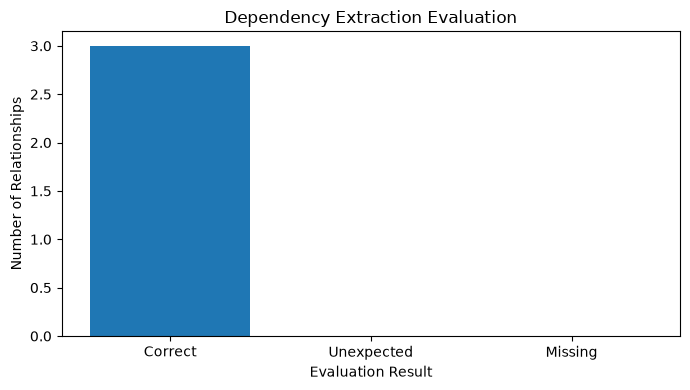

Chart saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\dependency_evaluation.png


In [40]:
# Cell 36
dependency_result_counts = pd.DataFrame({
    "Result": [
        "Correct",
        "Unexpected",
        "Missing"
    ],
    "Count": [
        dependency_tp,
        dependency_fp,
        dependency_fn
    ]
})

plt.figure(figsize=(7, 4))

plt.bar(
    dependency_result_counts["Result"],
    dependency_result_counts["Count"]
)

plt.title("Dependency Extraction Evaluation")
plt.xlabel("Evaluation Result")
plt.ylabel("Number of Relationships")
plt.tight_layout()

dependency_chart_path = (
    OUTPUT_DIR / "dependency_evaluation.png"
)

plt.savefig(
    dependency_chart_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Chart saved to:", dependency_chart_path)

In [41]:
# Cell 37
dependency_evaluation_report = {
    "document": PDF_PATH.name,
    "evaluation_scope": "Dependency relationship extraction",
    "expected_unique_dependencies": len(expected_dependency_records),
    "extracted_unique_dependencies": len(extracted_dependency_records),
    "true_positives": dependency_tp,
    "false_positives": dependency_fp,
    "false_negatives": dependency_fn,
    "precision": round(dependency_precision, 4),
    "recall": round(dependency_recall, 4),
    "f1_score": round(dependency_f1, 4),
    "ground_truth_status": (
        "Requires independent verification against the source HLD"
    )
}

dependency_report_path = (
    OUTPUT_DIR / "notebook06_dependency_evaluation.json"
)

with open(
    dependency_report_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        dependency_evaluation_report,
        file,
        indent=4,
        ensure_ascii=False
    )

print("DEPENDENCY EVALUATION REPORT")
print("=" * 50)

print(
    json.dumps(
        dependency_evaluation_report,
        indent=4,
        ensure_ascii=False
    )
)

print("\nSaved to:", dependency_report_path)

DEPENDENCY EVALUATION REPORT
{
    "document": "sample_autosar_hld.pdf",
    "evaluation_scope": "Dependency relationship extraction",
    "expected_unique_dependencies": 3,
    "extracted_unique_dependencies": 3,
    "true_positives": 3,
    "false_positives": 0,
    "false_negatives": 0,
    "precision": 1.0,
    "recall": 1.0,
    "f1_score": 1.0,
    "ground_truth_status": "Requires independent verification against the source HLD"
}

Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_dependency_evaluation.json


In [42]:
# Cell 38
interface_records = architecture_data.get("interfaces", [])

interface_df = pd.DataFrame(interface_records)

print("INTERFACE RECORD INSPECTION")
print("=" * 50)

print("Total interface records:", len(interface_df))
print("Available fields:", interface_df.columns.tolist())

display(interface_df)

if not interface_df.empty:
    print("\nFirst interface record:")
    print(
        json.dumps(
            interface_records[0],
            indent=4,
            ensure_ascii=False
        )
    )

INTERFACE RECORD INSPECTION
Total interface records: 3
Available fields: ['name', 'type', 'data_elements', 'provider', 'consumer', 'document', 'page', 'section_number', 'section_title']


,name,type,data_elements,provider,consumer,document,page,section_number,section_title
0,BatteryMeasurementInterface,Interface,"[BatteryVoltage, BatteryTemperature]",BatteryMonitor,ThermalController,sample_autosar_hld.pdf,3,6,Interface Definitions
1,BatteryStatusInterface,Interface,[BatteryStatus],BatteryMonitor,Dashboard,sample_autosar_hld.pdf,3,6,Interface Definitions
2,CoolingRequestInterface,Interface,[CoolingRequest],ThermalController,CoolingSystem,sample_autosar_hld.pdf,3,6,Interface Definitions



First interface record:
{
    "name": "BatteryMeasurementInterface",
    "type": "Interface",
    "data_elements": [
        "BatteryVoltage",
        "BatteryTemperature"
    ],
    "provider": "BatteryMonitor",
    "consumer": "ThermalController",
    "document": "sample_autosar_hld.pdf",
    "page": 3,
    "section_number": "6",
    "section_title": "Interface Definitions"
}


In [43]:
# Cell 39
port_records = architecture_data.get("ports", [])

port_df = pd.DataFrame(port_records)

print("PORT RECORD INSPECTION")
print("=" * 50)

print("Total port records:", len(port_df))
print("Available fields:", port_df.columns.tolist())

display(port_df)

if not port_df.empty:
    print("\nFirst port record:")
    print(
        json.dumps(
            port_records[0],
            indent=4,
            ensure_ascii=False
        )
    )

PORT RECORD INSPECTION
Total port records: 7
Available fields: ['name', 'component', 'direction', 'description', 'document', 'page', 'section_number', 'section_title', 'subsection_number']


,name,component,direction,description,document,page,section_number,section_title,subsection_number
0,P_BatteryVoltage,BatteryMonitor,Provider,battery voltage information.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.1
1,P_BatteryTemperature,BatteryMonitor,Provider,battery temperature information.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.1
2,P_BatteryStatus,BatteryMonitor,Provider,calculated battery status.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.1
3,R_BatteryTemperature,ThermalController,Receiver,battery temperature.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.2
4,P_CoolingRequest,ThermalController,Provider,the requested cooling state.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.2
5,R_BatteryStatus,Dashboard,Receiver,BatteryStatus.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.3
6,P_DisplayUpdate,Dashboard,Provider,the updated display information.,sample_autosar_hld.pdf,3,5,Ports and Interfaces,5.3



First port record:
{
    "name": "P_BatteryVoltage",
    "component": "BatteryMonitor",
    "direction": "Provider",
    "description": "battery voltage information.",
    "document": "sample_autosar_hld.pdf",
    "page": 3,
    "section_number": "5",
    "section_title": "Ports and Interfaces",
    "subsection_number": "5.1"
}


In [44]:
# Cell 40
def extract_unique_names(records, candidate_fields):
    names = []

    for record in records:
        if not isinstance(record, dict):
            continue

        for field in candidate_fields:
            value = record.get(field)

            if isinstance(value, str) and value.strip():
                names.append(value.strip())
                break

    return names


interface_names = extract_unique_names(
    interface_records,
    ["name", "interface", "interface_name"]
)

normalized_interface_names = [
    normalize_name(name)
    for name in interface_names
]

print("INTERFACE INVENTORY")
print("=" * 50)

for name in interface_names:
    print("-", name)

print("\nInterface records:", len(interface_records))
print("Names identified:", len(interface_names))
print(
    "Unique identified names:",
    len(set(normalized_interface_names))
)
print(
    "Duplicate identified names:",
    len(normalized_interface_names)
    - len(set(normalized_interface_names))
)

INTERFACE INVENTORY
- BatteryMeasurementInterface
- BatteryStatusInterface
- CoolingRequestInterface

Interface records: 3
Names identified: 3
Unique identified names: 3
Duplicate identified names: 0


In [45]:
# Cell 41
print("PORT DISTRIBUTION ANALYSIS")
print("=" * 50)

if port_df.empty:
    print("No port records are available.")
else:
    for field in [
        "name",
        "port",
        "port_name",
        "component",
        "component_name",
        "direction",
        "type"
    ]:
        if field in port_df.columns:
            print(f"\nDistribution by {field}:")
            display(
                port_df[field]
                .fillna("<missing>")
                .value_counts()
                .rename_axis(field)
                .reset_index(name="Count")
            )

    print("\nPort records analyzed:", len(port_df))

PORT DISTRIBUTION ANALYSIS

Distribution by name:


,name,Count
0,P_BatteryVoltage,1
1,P_BatteryTemperature,1
2,P_BatteryStatus,1
3,R_BatteryTemperature,1
4,P_CoolingRequest,1
5,R_BatteryStatus,1
6,P_DisplayUpdate,1



Distribution by component:


,component,Count
0,BatteryMonitor,3
1,ThermalController,2
2,Dashboard,2



Distribution by direction:


,direction,Count
0,Provider,5
1,Receiver,2



Port records analyzed: 7


In [46]:
# Cell 42
interface_port_profile = {
    "document": PDF_PATH.name,
    "interface_record_count": len(interface_records),
    "port_record_count": len(port_records),
    "interface_fields": interface_df.columns.tolist(),
    "port_fields": port_df.columns.tolist(),
    "interface_names_identified": interface_names,
    "unique_interface_names": len(
        set(normalized_interface_names)
    ),
    "interface_names_missing_or_unrecognized": (
        len(interface_records) - len(interface_names)
    )
}

interface_port_profile_path = (
    OUTPUT_DIR / "notebook06_interface_port_profile.json"
)

with open(
    interface_port_profile_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        interface_port_profile,
        file,
        indent=4,
        ensure_ascii=False
    )

print("INTERFACE AND PORT PROFILE")
print("=" * 50)

print(
    json.dumps(
        interface_port_profile,
        indent=4,
        ensure_ascii=False
    )
)

print("\nSaved to:", interface_port_profile_path)

INTERFACE AND PORT PROFILE
{
    "document": "sample_autosar_hld.pdf",
    "interface_record_count": 3,
    "port_record_count": 7,
    "interface_fields": [
        "name",
        "type",
        "data_elements",
        "provider",
        "consumer",
        "document",
        "page",
        "section_number",
        "section_title"
    ],
    "port_fields": [
        "name",
        "component",
        "direction",
        "description",
        "document",
        "page",
        "section_number",
        "section_title",
        "subsection_number"
    ],
    "interface_names_identified": [
        "BatteryMeasurementInterface",
        "BatteryStatusInterface",
        "CoolingRequestInterface"
    ],
    "unique_interface_names": 3,
    "interface_names_missing_or_unrecognized": 0
}

Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_interface_port_profile.json


In [47]:
# Cell 43
expected_interfaces = {
    "BatteryMeasurementInterface",
    "BatteryStatusInterface",
    "CoolingRequestInterface"
}

extracted_interfaces = {
    normalize_name(record.get("name"))
    for record in interface_records
    if isinstance(record, dict)
    and normalize_name(record.get("name"))
}

expected_interfaces_normalized = {
    normalize_name(name)
    for name in expected_interfaces
}

correct_interfaces = (
    extracted_interfaces & expected_interfaces_normalized
)

unexpected_interfaces = (
    extracted_interfaces - expected_interfaces_normalized
)

missing_interfaces = (
    expected_interfaces_normalized - extracted_interfaces
)

print("INTERFACE NAME EVALUATION")
print("=" * 50)
print("Expected interfaces:", len(expected_interfaces_normalized))
print("Extracted interfaces:", len(extracted_interfaces))
print("Correct:", len(correct_interfaces))
print("Unexpected:", len(unexpected_interfaces))
print("Missing:", len(missing_interfaces))

print("\nUnexpected interfaces:", sorted(unexpected_interfaces))
print("Missing interfaces:", sorted(missing_interfaces))

INTERFACE NAME EVALUATION
Expected interfaces: 3
Extracted interfaces: 3
Correct: 3
Unexpected: 0
Missing: 0

Unexpected interfaces: []
Missing interfaces: []


In [48]:
# Cell 44
interface_tp = len(correct_interfaces)
interface_fp = len(unexpected_interfaces)
interface_fn = len(missing_interfaces)

interface_precision = (
    interface_tp / (interface_tp + interface_fp)
    if interface_tp + interface_fp else 0.0
)

interface_recall = (
    interface_tp / (interface_tp + interface_fn)
    if interface_tp + interface_fn else 0.0
)

interface_f1 = (
    2 * interface_precision * interface_recall
    / (interface_precision + interface_recall)
    if interface_precision + interface_recall else 0.0
)

print(f"Interface precision: {interface_precision:.2%}")
print(f"Interface recall:    {interface_recall:.2%}")
print(f"Interface F1-score:  {interface_f1:.2%}")

Interface precision: 100.00%
Interface recall:    100.00%
Interface F1-score:  100.00%


In [49]:
# Cell 45
required_port_fields = ["name", "component", "direction"]

port_quality_rows = []

for index, record in enumerate(port_records):
    row = {
        "Record Index": index,
        "Port Name": record.get("name"),
        "Component": record.get("component"),
        "Direction": record.get("direction")
    }

    for field in required_port_fields:
        value = record.get(field)

        row[f"{field}_missing"] = (
            value is None
            or (isinstance(value, str) and not value.strip())
        )

    port_quality_rows.append(row)

port_quality_df = pd.DataFrame(port_quality_rows)

display(port_quality_df)

for field in required_port_fields:
    missing_count = int(
        port_quality_df[f"{field}_missing"].sum()
    )

    print(f"Missing {field} values: {missing_count}")

,Record Index,Port Name,Component,Direction,name_missing,component_missing,direction_missing
0,0,P_BatteryVoltage,BatteryMonitor,Provider,False,False,False
1,1,P_BatteryTemperature,BatteryMonitor,Provider,False,False,False
2,2,P_BatteryStatus,BatteryMonitor,Provider,False,False,False
3,3,R_BatteryTemperature,ThermalController,Receiver,False,False,False
4,4,P_CoolingRequest,ThermalController,Provider,False,False,False
5,5,R_BatteryStatus,Dashboard,Receiver,False,False,False
6,6,P_DisplayUpdate,Dashboard,Provider,False,False,False


Missing name values: 0
Missing component values: 0
Missing direction values: 0


In [51]:
# Cell 46
port_reference_results = []

for index, record in enumerate(port_records):
    component_value = normalize_name(record.get("component"))

    if component_value is None:
        status = "Missing component reference"
    elif component_value in internal_components:
        status = "Valid internal component"
    elif component_value in external_entities:
        status = "Known external entity"
    else:
        status = "Unclassified component"

    port_reference_results.append({
        "Port": record.get("name"),
        "Component": record.get("component"),
        "Classification": status
    })

port_reference_df = pd.DataFrame(port_reference_results)

display(port_reference_df)

print("\nPort reference summary:")
display(
    port_reference_df["Classification"]
    .value_counts()
    .rename_axis("Classification")
    .reset_index(name="Count")
)

,Port,Component,Classification
0,P_BatteryVoltage,BatteryMonitor,Valid internal component
1,P_BatteryTemperature,BatteryMonitor,Valid internal component
2,P_BatteryStatus,BatteryMonitor,Valid internal component
3,R_BatteryTemperature,ThermalController,Valid internal component
4,P_CoolingRequest,ThermalController,Valid internal component
5,R_BatteryStatus,Dashboard,Valid internal component
6,P_DisplayUpdate,Dashboard,Valid internal component



Port reference summary:


,Classification,Count
0,Valid internal component,7


In [52]:
# Cell 46
port_reference_results = []

for index, record in enumerate(port_records):
    component_value = normalize_name(record.get("component"))

    if component_value is None:
        status = "Missing component reference"
    elif component_value in internal_components:
        status = "Valid internal component"
    elif component_value in external_entities:
        status = "Known external entity"
    else:
        status = "Unclassified component"

    port_reference_results.append({
        "Port": record.get("name"),
        "Component": record.get("component"),
        "Classification": status
    })

port_reference_df = pd.DataFrame(port_reference_results)

display(port_reference_df)

print("\nPort reference summary:")
display(
    port_reference_df["Classification"]
    .value_counts()
    .rename_axis("Classification")
    .reset_index(name="Count")
)

,Port,Component,Classification
0,P_BatteryVoltage,BatteryMonitor,Valid internal component
1,P_BatteryTemperature,BatteryMonitor,Valid internal component
2,P_BatteryStatus,BatteryMonitor,Valid internal component
3,R_BatteryTemperature,ThermalController,Valid internal component
4,P_CoolingRequest,ThermalController,Valid internal component
5,R_BatteryStatus,Dashboard,Valid internal component
6,P_DisplayUpdate,Dashboard,Valid internal component



Port reference summary:


,Classification,Count
0,Valid internal component,7


In [53]:
# Cell 47
interface_port_evaluation = {
    "document": PDF_PATH.name,
    "interface_records": len(interface_records),
    "expected_interface_names": len(expected_interfaces_normalized),
    "extracted_interface_names": len(extracted_interfaces),
    "interface_true_positives": interface_tp,
    "interface_false_positives": interface_fp,
    "interface_false_negatives": interface_fn,
    "interface_precision": round(interface_precision, 4),
    "interface_recall": round(interface_recall, 4),
    "interface_f1_score": round(interface_f1, 4),
    "port_records": len(port_records),
    "ports_missing_names": int(port_quality_df["name_missing"].sum()),
    "ports_missing_components": int(
        port_quality_df["component_missing"].sum()
    ),
    "ports_missing_directions": int(
        port_quality_df["direction_missing"].sum()
    ),
    "port_component_classifications": {
        str(key): int(value)
        for key, value in (
            port_reference_df["Classification"].value_counts().items()
        )
    },
    "ground_truth_status": (
        "Interface names require verification against the source HLD; "
        "port completeness is a structural check, not port extraction accuracy."
    )
}

interface_port_evaluation_path = (
    OUTPUT_DIR / "notebook06_interface_port_evaluation.json"
)

with open(
    interface_port_evaluation_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        interface_port_evaluation,
        file,
        indent=4,
        ensure_ascii=False
    )

print("INTERFACE AND PORT EVALUATION")
print("=" * 50)
print(json.dumps(interface_port_evaluation, indent=4, ensure_ascii=False))
print("\nSaved to:", interface_port_evaluation_path)

INTERFACE AND PORT EVALUATION
{
    "document": "sample_autosar_hld.pdf",
    "interface_records": 3,
    "expected_interface_names": 3,
    "extracted_interface_names": 3,
    "interface_true_positives": 3,
    "interface_false_positives": 0,
    "interface_false_negatives": 0,
    "interface_precision": 1.0,
    "interface_recall": 1.0,
    "interface_f1_score": 1.0,
    "port_records": 7,
    "ports_missing_names": 0,
    "ports_missing_components": 0,
    "ports_missing_directions": 0,
    "port_component_classifications": {
        "Valid internal component": 7
    },
    "ground_truth_status": "Interface names require verification against the source HLD; port completeness is a structural check, not port extraction accuracy."
}

Saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_interface_port_evaluation.json


In [54]:
# Cell 48
functional_flow_records = architecture_data.get("functional_flows", [])
data_flow_records = architecture_data.get("data_flows", [])

functional_flow_df = pd.DataFrame(functional_flow_records)
data_flow_df = pd.DataFrame(data_flow_records)

print("FUNCTIONAL FLOWS")
print("=" * 50)
print("Records:", len(functional_flow_df))
print("Fields:", functional_flow_df.columns.tolist())
display(functional_flow_df)

print("\nDATA FLOWS")
print("=" * 50)
print("Records:", len(data_flow_df))
print("Fields:", data_flow_df.columns.tolist())
display(data_flow_df)

FUNCTIONAL FLOWS
Records: 6
Fields: ['step', 'description', 'document', 'page', 'section_number', 'section_title']


,step,description,document,page,section_number,section_title
0,1,BatteryMonitor reads battery voltage and tempe...,sample_autosar_hld.pdf,4,8,Functional Flow
1,2,BatteryMonitor calculates BatteryStatus.,sample_autosar_hld.pdf,4,8,Functional Flow
2,3,BatteryMonitor provides BatteryTemperature to ...,sample_autosar_hld.pdf,4,8,Functional Flow
3,4,ThermalController evaluates the temperature an...,sample_autosar_hld.pdf,4,8,Functional Flow
4,5,BatteryMonitor provides BatteryStatus to Dashb...,sample_autosar_hld.pdf,4,8,Functional Flow
5,6,Dashboard updates the driver display.,sample_autosar_hld.pdf,4,8,Functional Flow



DATA FLOWS
Records: 5
Fields: ['signal', 'relationship', 'component', 'document', 'page', 'section_number', 'section_title']


,signal,relationship,component,document,page,section_number,section_title
0,BatteryVoltage,produced,BatteryMonitor,sample_autosar_hld.pdf,4,7,Signals and Data Flow
1,BatteryTemperature,produced,BatteryMonitor,sample_autosar_hld.pdf,4,7,Signals and Data Flow
2,BatteryStatus,consumed,Dashboard,sample_autosar_hld.pdf,4,7,Signals and Data Flow
3,BatteryTemperature,consumed,ThermalController,sample_autosar_hld.pdf,4,7,Signals and Data Flow
4,CoolingRequest,generated,ThermalController,sample_autosar_hld.pdf,4,7,Signals and Data Flow


In [55]:
# Cell 49
functional_flow_quality = []

for index, record in enumerate(functional_flow_records):
    if not isinstance(record, dict):
        continue

    functional_flow_quality.append({
        "Record Index": index,
        "Fields Present": len(record),
        "Empty Fields": sum(
            value is None
            or (isinstance(value, str) and not value.strip())
            for value in record.values()
        ),
        "Document Present": bool(record.get("document")),
        "Page Present": record.get("page") is not None
    })

functional_flow_quality_df = pd.DataFrame(functional_flow_quality)

display(functional_flow_quality_df)

print(
    "\nFunctional-flow records checked:",
    len(functional_flow_quality_df)
)

print(
    "Records with empty fields:",
    int(functional_flow_quality_df["Empty Fields"].gt(0).sum())
    if not functional_flow_quality_df.empty else 0
)

print(
    "Records with document traceability:",
    int(functional_flow_quality_df["Document Present"].sum())
    if not functional_flow_quality_df.empty else 0
)

print(
    "Records with page traceability:",
    int(functional_flow_quality_df["Page Present"].sum())
    if not functional_flow_quality_df.empty else 0
)

,Record Index,Fields Present,Empty Fields,Document Present,Page Present
0,0,6,0,True,True
1,1,6,0,True,True
2,2,6,0,True,True
3,3,6,0,True,True
4,4,6,0,True,True
5,5,6,0,True,True



Functional-flow records checked: 6
Records with empty fields: 0
Records with document traceability: 6
Records with page traceability: 6


In [56]:
# Cell 50
data_flow_quality = []

for index, record in enumerate(data_flow_records):
    if not isinstance(record, dict):
        continue

    data_flow_quality.append({
        "Record Index": index,
        "Fields Present": len(record),
        "Empty Fields": sum(
            value is None
            or (isinstance(value, str) and not value.strip())
            for value in record.values()
        ),
        "Document Present": bool(record.get("document")),
        "Page Present": record.get("page") is not None
    })

data_flow_quality_df = pd.DataFrame(data_flow_quality)

display(data_flow_quality_df)

print("\nData-flow records checked:", len(data_flow_quality_df))

print(
    "Records with empty fields:",
    int(data_flow_quality_df["Empty Fields"].gt(0).sum())
    if not data_flow_quality_df.empty else 0
)

print(
    "Records with document traceability:",
    int(data_flow_quality_df["Document Present"].sum())
    if not data_flow_quality_df.empty else 0
)

print(
    "Records with page traceability:",
    int(data_flow_quality_df["Page Present"].sum())
    if not data_flow_quality_df.empty else 0
)

,Record Index,Fields Present,Empty Fields,Document Present,Page Present
0,0,7,0,True,True
1,1,7,0,True,True
2,2,7,0,True,True
3,3,7,0,True,True
4,4,7,0,True,True



Data-flow records checked: 5
Records with empty fields: 0
Records with document traceability: 5
Records with page traceability: 5


In [57]:
# Cell 51
report_files = {
    "data_quality": "notebook06_data_quality_report.json",
    "architecture_consistency": "notebook06_architecture_consistency.json",
    "component_evaluation": "notebook06_component_evaluation.json",
    "dependency_evaluation": "notebook06_dependency_evaluation.json",
    "interface_port_evaluation": "notebook06_interface_port_evaluation.json"
}

consolidated_report = {
    "document": PDF_PATH.name,
    "eda_summary": eda_summary,
    "reports": {}
}

for report_name, filename in report_files.items():
    report_path = OUTPUT_DIR / filename

    if report_path.exists():
        with open(report_path, "r", encoding="utf-8") as file:
            consolidated_report["reports"][report_name] = json.load(file)
    else:
        consolidated_report["reports"][report_name] = {
            "status": "Report not found",
            "expected_file": filename
        }

consolidated_report["flow_completeness"] = {
    "functional_flow_records": len(functional_flow_records),
    "functional_flow_records_checked": len(functional_flow_quality_df),
    "data_flow_records": len(data_flow_records),
    "data_flow_records_checked": len(data_flow_quality_df)
}

consolidated_path = OUTPUT_DIR / "notebook06_consolidated_report.json"

with open(consolidated_path, "w", encoding="utf-8") as file:
    json.dump(
        consolidated_report,
        file,
        indent=4,
        ensure_ascii=False
    )

print("Consolidated report saved to:", consolidated_path)
print("Report sections:", list(consolidated_report.keys()))
print("Evaluation reports included:", len(consolidated_report["reports"]))

Consolidated report saved to: c:\Users\preet\OneDrive\Desktop\autosar_hld_assistant\eval\results\notebook06_consolidated_report.json
Report sections: ['document', 'eda_summary', 'reports', 'flow_completeness']
Evaluation reports included: 5
